# 03 Multi node

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().parent
FIGURES = ANALYSIS_DIR / 'figures'
sys.path.insert(0, str(ANALYSIS_DIR))

from src.data_loader import load_multi_node
from src.statistics import (
    combine_attackers,
    saturation_rate,
    slo_capacity,
    summarize,
)

plt.rcParams.update(
    {
        'figure.figsize': (7, 4),
        'figure.dpi': 110,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.3,
    }
)
SINGLE, MULTI = '#2a78d6', '#eb6834'
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
SLOS_MS = [1, 10, 100]
SATURATION_TOLERANCE = 0.95

In [3]:
multi = load_multi_node()
runs = combine_attackers(multi)
attackers = sorted(multi['attacker'].unique())
if runs['n_attackers'].min() < 2:
    print(
        f'WARNING: only {attackers} present. Throughput below is what these attackers saw '
        '(offered = rate / 2 per attacker), not the full cluster.'
    )
attackers

['node1', 'node3']

## Per attacker

In [4]:
summarize(
    multi,
    ['rate', 'attacker'],
    ['throughput', 'success', 'lat_p50_ms', 'lat_p99_ms'],
).filter(regex='rate|attacker|_mean$')

,rate,attacker,throughput_mean,success_mean,lat_p50_ms_mean,lat_p99_ms_mean
0,2000,node1,1000.011,1.000,0.260,0.578
1,2000,node3,1000.003,1.000,0.260,0.576
2,4000,node1,2000.028,1.000,0.260,0.741
3,4000,node3,2000.011,1.000,0.259,0.739
4,6000,node1,3000.036,1.000,0.277,0.809
5,6000,node3,3000.025,1.000,0.277,0.806
6,8000,node1,3999.969,1.000,0.272,0.870
7,8000,node3,3999.988,1.000,0.273,0.874
8,10000,node1,4999.969,1.000,0.237,0.769
9,10000,node3,4999.996,1.000,0.237,0.770


## Aggregate

In [5]:
agg = summarize(
    runs,
    ['rate', 'offered'],
    [
        'throughput',
        'success',
        'lat_mean_ms',
        'lat_p99_ms',
        'node0_cpu',
        'node2_cpu',
    ],
)
agg.filter(regex='rate|offered|_mean$|_ci95$')

,rate,offered,throughput_mean,throughput_ci95,success_mean,success_ci95,lat_mean_ms_mean,lat_mean_ms_ci95,lat_p99_ms_mean,lat_p99_ms_ci95,node0_cpu_mean,node0_cpu_ci95,node2_cpu_mean,node2_cpu_ci95
0,2000,2000.000,2000.014,0.014,1.000,0.000,0.272,0.005,0.585,0.010,11.131,0.791,8.181,0.079
1,4000,4000.000,4000.039,0.024,1.000,0.000,0.287,0.002,0.746,0.008,22.928,0.254,15.834,0.047
2,6000,6000.000,6000.061,0.040,1.000,0.000,0.320,0.002,0.814,0.003,32.461,0.686,22.740,0.105
3,8000,8000.000,7999.957,0.093,1.000,0.000,0.337,0.001,0.878,0.007,43.530,0.763,30.469,0.054
4,10000,10000.000,9999.965,0.097,1.000,0.000,0.284,0.002,0.780,0.005,55.486,0.593,38.638,0.107
5,12000,12000.000,11999.994,0.017,1.000,0.000,0.294,0.003,0.748,0.005,65.052,2.063,45.913,0.131
6,14000,14000.000,13999.958,0.077,1.000,0.000,0.287,0.003,0.755,0.009,48.979,0.303,53.009,0.263
7,16000,16000.000,15999.917,0.064,1.000,0.000,0.329,0.007,0.815,0.017,55.706,0.427,59.704,0.165
8,18000,18000.000,17999.819,0.046,1.000,0.000,0.438,0.030,1.941,1.262,61.753,0.439,65.402,0.226
9,20000,20000.000,19999.793,0.079,1.000,0.000,1.445,0.027,14.484,0.408,68.420,0.734,53.284,2.196


In [6]:
saturation = saturation_rate(
    agg, offered_col='offered', tolerance=SATURATION_TOLERANCE
)
capacity = {
    f'p99 <= {slo} ms': slo_capacity(agg, 'lat_p99_ms_mean', slo)
    for slo in SLOS_MS
}
print(f'saturation (aggregate offered rate): {saturation} req/s')
capacity

saturation (aggregate offered rate): 38000 req/s


{'p99 <= 1 ms': 16000, 'p99 <= 10 ms': 18000, 'p99 <= 100 ms': 38000}

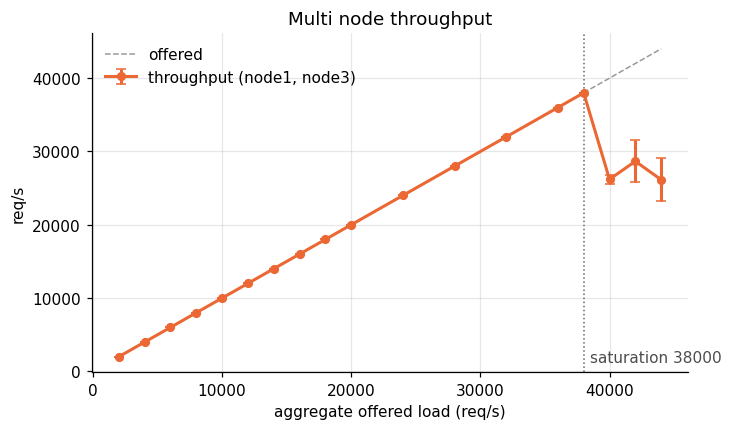

In [7]:
fig, ax = plt.subplots()
ax.plot(
    agg['rate'], agg['offered'], color='0.6', ls='--', lw=1, label='offered'
)
ax.errorbar(
    agg['rate'],
    agg['throughput_mean'],
    yerr=agg['throughput_ci95'],
    color=MULTI,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label=f'throughput ({", ".join(attackers)})',
)
ax.axvline(saturation, color='0.4', lw=1, ls=':')
ax.annotate(
    f'saturation {saturation}',
    (saturation, 0),
    xytext=(4, 6),
    textcoords='offset points',
    color='0.3',
)
ax.set(
    xlabel='aggregate offered load (req/s)',
    ylabel='req/s',
    title='Multi node throughput',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '03_throughput.png')

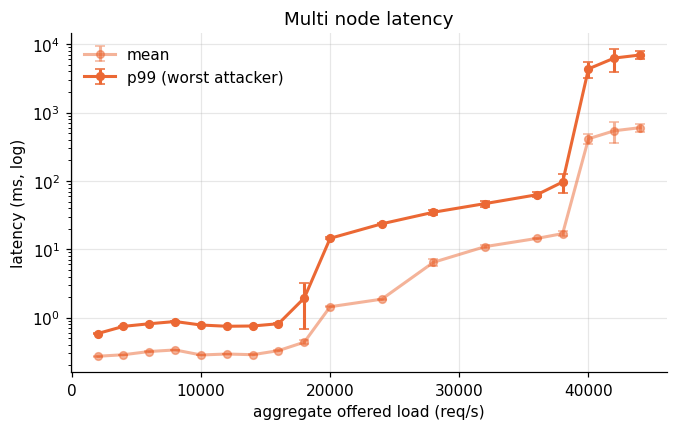

In [8]:
fig, ax = plt.subplots()
ax.errorbar(
    agg['rate'],
    agg['lat_mean_ms_mean'],
    yerr=agg['lat_mean_ms_ci95'],
    color=MULTI,
    alpha=0.5,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='mean',
)
ax.errorbar(
    agg['rate'],
    agg['lat_p99_ms_mean'],
    yerr=agg['lat_p99_ms_ci95'],
    color=MULTI,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='p99 (worst attacker)',
)
ax.set(
    yscale='log',
    xlabel='aggregate offered load (req/s)',
    ylabel='latency (ms, log)',
    title='Multi node latency',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '03_latency.png')

## Load balance across servers

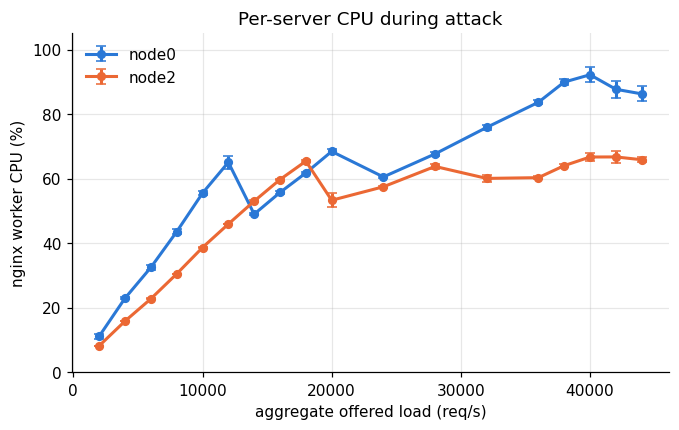

In [9]:
fig, ax = plt.subplots()
for server, color in [('node0', SINGLE), ('node2', MULTI)]:
    ax.errorbar(
        agg['rate'],
        agg[f'{server}_cpu_mean'],
        yerr=agg[f'{server}_cpu_ci95'],
        color=color,
        lw=2,
        marker='o',
        ms=5,
        capsize=3,
        label=server,
    )
ax.set(
    xlabel='aggregate offered load (req/s)',
    ylabel='nginx worker CPU (%)',
    ylim=(0, 105),
    title='Per-server CPU during attack',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '03_cpu_per_server.png')

In [10]:
(agg['node0_cpu_mean'] - agg['node2_cpu_mean']).rename(
    'node0 - node2 CPU (pp)'
).to_frame().set_index(agg['rate'])

,node0 - node2 CPU (pp)
rate,
2000,2.950
4000,7.094
6000,9.721
8000,13.061
10000,16.848
12000,19.139
14000,-4.031
16000,-3.999
18000,-3.649
